# Assignment 2

# Overview

Implement various supervised learning algorithms, optimize them through hyperparameter tuning using cross-validation, and evaluate their performance on a provided breast cancer dataset.

* Use best practice machine learning workflow to produce a solution to a client's problem.
* Visualize and explore the data, ensuring thorough understanding and insights.
* Create necessary datasets for training, validation, and testing, maintaining appropriate class distributions through stratified sampling.
* Implement a preprocessing pipeline to enhance model performance.
* Create pipelines for classifiers and implement multiple machine learning models, including Decision Tree, Random Forest, and Support Vector Machine (SVM).
* Optimize models through hyperparameter tuning to select the best-performing model.
* Obtain unbiased measurement of final model performance using validation metrics, including accuracy, precision, recall, and F1-score.
* Summarize and compare all model results to identify the best-performing solution for the client’s requirements.
* Implement and evaluate a neural network for classification, comparing its performance with other machine learning models.
* Introduce ensemble techniques, including bagging with Random Forest and boosting with AdaBoost and XGBoost, to improve model performance and stability.
* Clearly and concisely interpret and communicate results, including predictions and probability estimates for new data.



# General instructions
This assignment is divided into several tasks. Use the spaces provided in this notebook to answer the questions posed in each task. Note that some questions require writing a small amount of code, some require graphical results.
Do not manually edit the data set file we have provided! For marking purposes, it's important that your code runs correctly on the original data file.
Some of the parts of this assignment build on the workflow from the first assignment and that part of the course, and so less detailed instructions are provided for this, as you should be able to implement this workflow now without low-level guidance. A substantial portion of the marks for this assignment are associated with making the right choices and executing this workflow correctly and efficiently.

This assignment can be solved using methods from sklearn, pandas, and matplotlib as presented in the workshops. Other libraries should not be used (even though they might have nice functionality) and certain restrictions on sklearn functions will be made clear in the instruction text. You are expected to search and carefully read the documentation for functions that you use, to ensure you are using them correctly.

# Scenario

A client approaches you to solve a machine learning problem for them. They run a pathology lab that processes histological images for healthcare providers and they have created a product that measures the same features as in the *Wisconsin breast cancer data set* though using different acquisitions and processing methods. This makes their method much faster than existing ones, but it is also slightly noisier. The dataset contains measurements of several features that describe characteristics of cell nuclei present in digital images of breast tissue samples. These features include the mean, standard error, and "worst" (i.e., largest) values of measurements such as radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension. Each feature is represented by a numeric value, and each data point represents a sample from either a malignant (cancerous) or benign (non-cancerous) breast tissue.

The client want to be able to diagnose *malignant* cancer (and distinguish them from *benign* growths) by employing machine learning techniques, and they have asked you to implement this for them.

Their requirements are:

1. have at least a 95% probability of detecting malignant cancer when it is present;
2. have no more than 1 in 10 healthy cases (those with benign tumours) labelled as positive (malignant).

They have hand-labelled 300 samples for you, which is all they have at the moment.

Please follow the instructions below, which will vary in level of detail, as appropriate to the marks given.

**Step 1** [1 point] (5%)

Load the dataset Do this from the csv file, `assignment2.csv`. Extract the feature names for use later on. The first column is our target and it contains the labels (benign and malignant). Note that we will be treating the _malignant_ case as our _positive_ case, as this is the standard convention in medicine.

In [18]:
# Import necessary libraries
import pandas as pd

# Load the dataset from 'assignment2.csv'
data = pd.read_csv('assignment2.csv')
print(data.columns)

# Extract feature names (excluding the first column, which contains labels)
feature_names = data.columns[1:] # exclude first column

# The following code is used by the autograder
# make sure your variable that contains the answer from this step is the one assigned to step1_data
step1_data = feature_names
print(step1_data)
print(data)
print(data.isna().sum())

Index(['label', 'mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='object')
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'co

Step 2:Data Exploration (10%):

To familiarise yourself with the nature and information contained in the data, display histograms for the data according to the following instructions:
* Isolate each group of features (mean, standard error, and worst) into its own DataFrame.
* You are provided with code to display histograms for each feature in the mean group. On each histogram the two classes displayed together in one plot.
* Repeat this for the standard error and worst groups;
* Based on the histograms and using the function corr() or numpy corrcoef() which do you think are the 3 strongest features for discriminating between the classes?

            label  mean radius  mean texture  mean perimeter    mean area  \
count  300.000000   300.000000    300.000000      300.000000   300.000000   
mean     0.486667    14.231808     19.312619       92.727687   664.367372   
std      0.500657     1.297393      1.572224        8.949937   129.515717   
min      0.000000    11.560025     15.349270       74.690886   477.371592   
25%      0.000000    13.356676     18.194791       86.659535   580.383274   
50%      0.000000    13.976933     19.220652       90.896982   628.004851   
75%      1.000000    15.103078     20.245660       99.093762   737.444716   
max      1.000000    19.090091     26.836291      126.168030  1300.788708   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       300.000000        300.000000      300.000000           300.000000   
mean          0.096937          0.106615        0.092591             0.050820   
std           0.005067          0.020819        0.030312       

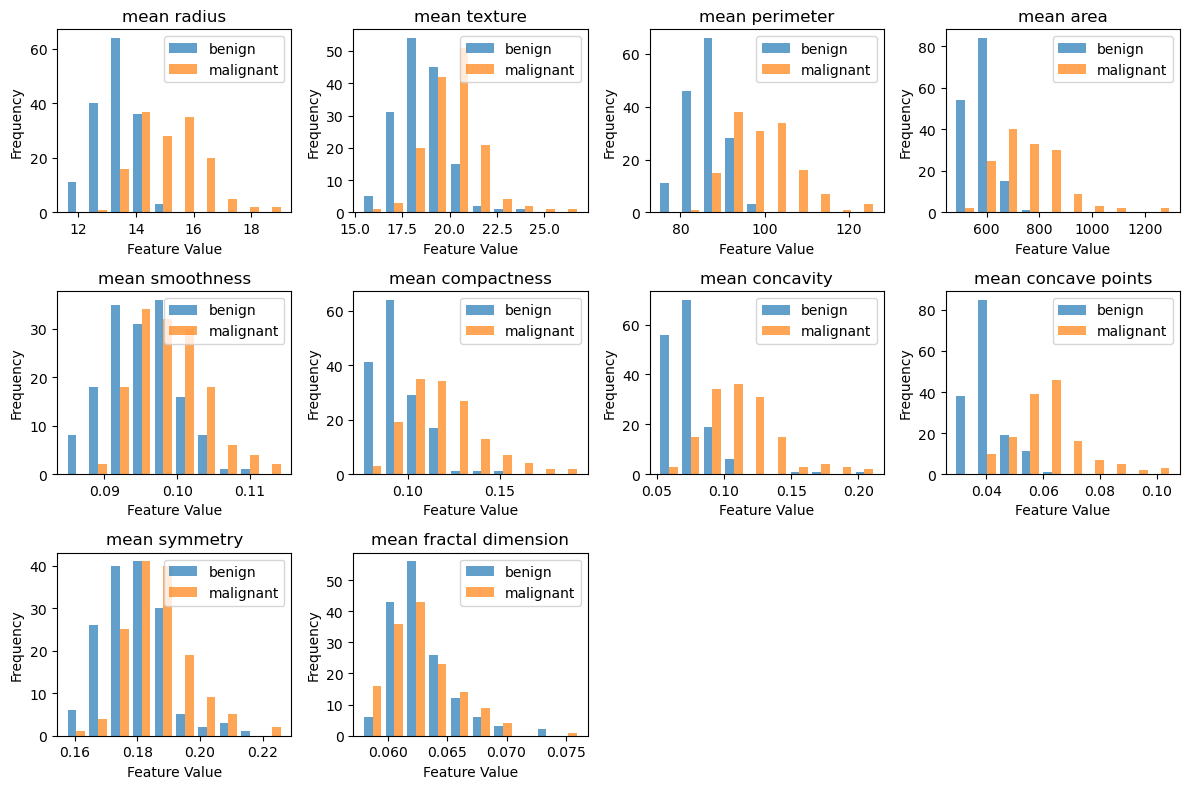

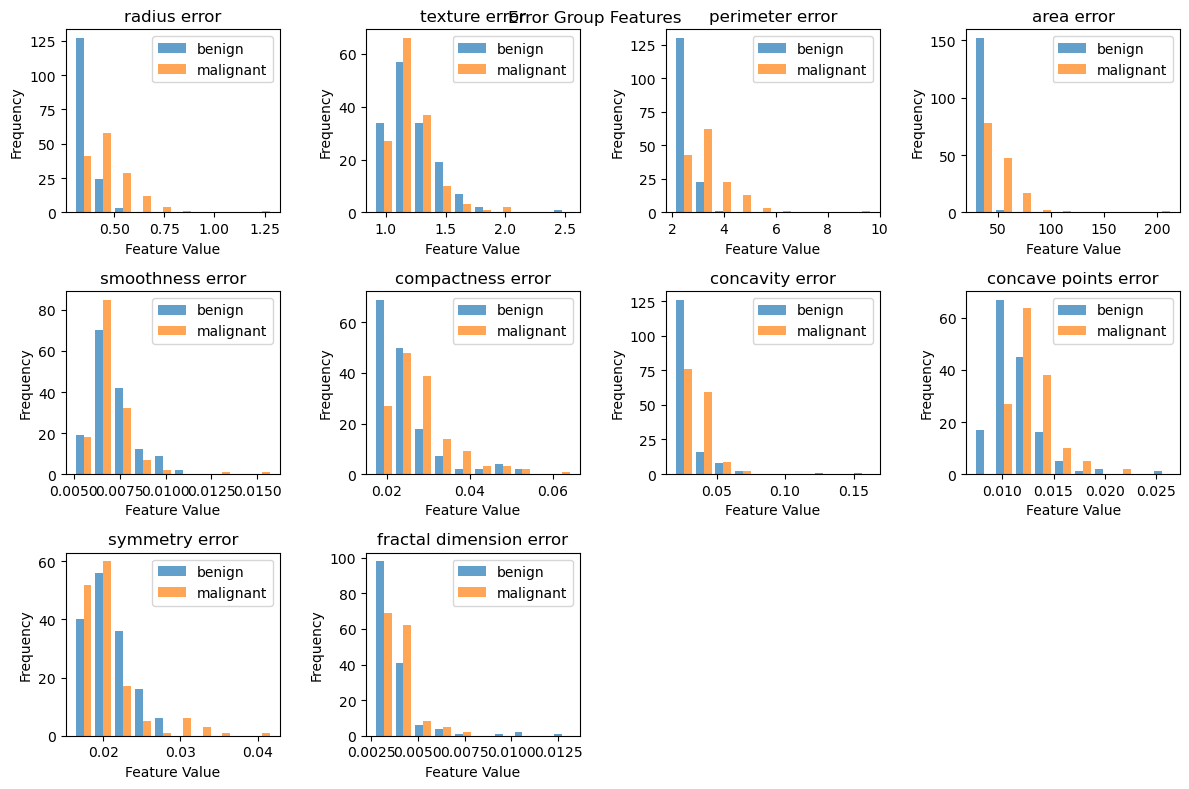

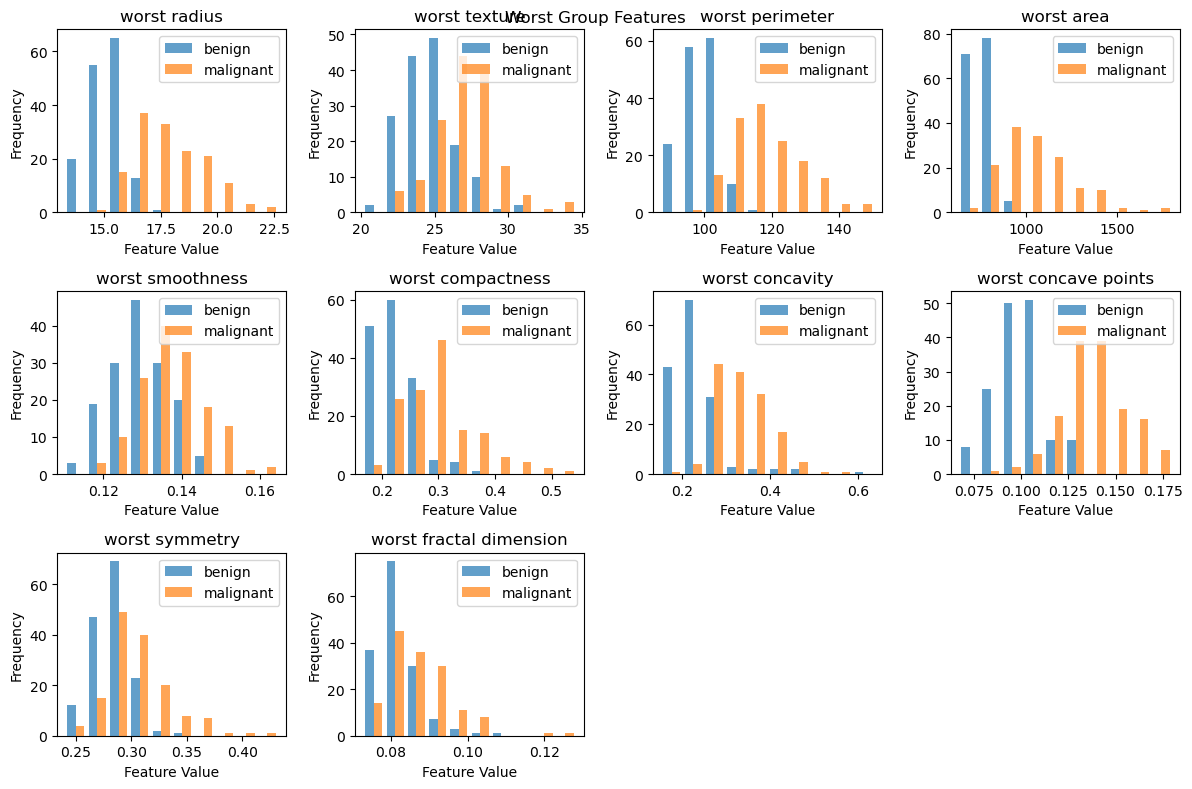

Top three strongest features for discriminating between classes (all groups):
worst concave points
worst perimeter
worst radius


In [19]:

# Import necessary libraries
import matplotlib.pyplot as plt

# Convert labels to numeric format (0 for benign, 1 for malignant)
data['label'] = data['label'].map({'benign': 0, 'malignant': 1})
# print(data)
# print(data['label'])

# Separate the mean, standard error, and worst groups into separate DataFrames
mean_group = data.filter(like='mean') # separate feature groups based on column names
error_group = data.filter(like='error')
worst_group = data.filter(like='worst')
# print(mean_group)
# print(error_group)
# print(worst_group)

# Display basic statistics of the dataset
print(data.describe()) # IMPORTANT

# Plot histograms for each feature in the mean group with both classes displayed together
class_labels = ['benign', 'malignant'] # labels for histogram
fig = plt.figure(figsize=(12, 8))

# Plot histograms for mean group- no change in this part
# for i, feature in enumerate(mean_group.columns):
#     print(mean_group)
for i, feature in enumerate(mean_group.columns):
    plt.subplot(3, 4, i + 1)
    plt.hist([mean_group[feature][data['label'] == 0],
              mean_group[feature][data['label'] == 1]],
             label=class_labels, alpha=0.7)
    plt.xlabel("Feature Value")
    plt.ylabel("Frequency")
    plt.legend()
    plt.title(feature)

plt.tight_layout()
plt.show()

# Plot histograms for error and worst groups-no change in this part
for group, title in zip([error_group, worst_group], ['Error Group Features', 'Worst Group Features']):
    fig = plt.figure(figsize=(12, 8))
    for i, feature in enumerate(group.columns):
        # print(group[feature])
        plt.subplot(3, 4, i + 1)
        plt.hist([group[feature][data['label'] == 0],
                  group[feature][data['label'] == 1]],
                 label=class_labels, alpha=0.7)
        plt.xlabel("Feature Value")
        plt.ylabel("Frequency")
        plt.legend()
        plt.title(feature)

    plt.tight_layout()
    plt.suptitle(title)
    plt.show()

# Calculate correlation matrix for all features including label
correlation_matrix = data.corr() #
# print(correlation_matrix)

label_corr = correlation_matrix['label'].drop('label').abs()

# Get the top three strongest features correlated with the label
strongest_features = label_corr.sort_values(ascending=False).head(3) # top 3 strongest features
ranked_features = strongest_features.index.tolist()
# print(ranked_features)

# Print the top three strongest features for all groups
print("Top three strongest features for discriminating between classes (all groups):")
for feature in ranked_features:
    print(feature)

# The following code is used by the autograder
step2_data = ranked_features  # Store only the top three features


Step3: **Data Splitting (10%):**
* Identify your feature set and the target variable (the label column indicating benign or malignant).
* Split the Dataset:
Begin by splitting the dataset into a training set and a temporary set. Use 80% of the data for training and 20% for the temporary set.
* Create Validation and Test Sets:
From the temporary set (20% of the original data), further divide it into validation and test sets. Allocate 50% of this temporary set to the validation set and 50% to the test set.
This results in the final dataset comprising 80% for training, 10% for validation, and 10% for testing.
* When splitting the dataset, utilize the stratify option to ensure that the distribution of classes (benign and malignant) is preserved in both the training and temporary sets.
* After performing the splits, confirm the sizes of each subset

In [20]:
from sklearn.model_selection import train_test_split

# Split the data into features and labels
X = data.drop(columns=['label']) # feature metrics
y = data['label'] # target labels
print(data)

# Split into training and temporary (validation + test) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42) # split into train (80%) and temp (20%)

# Split the temporary set into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42) # split temp into validation (10%) and test (10%)

# Print the size of each resulting subset
print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step3_data
step3_data = (X_train, X_val, X_test)



     label  mean radius  mean texture  mean perimeter   mean area  \
0        1    15.494654     15.902542      103.008265  776.437239   
1        1    16.229871     18.785613      105.176755  874.712003   
2        1    16.345671     20.114076      107.083804  872.563251   
3        1    13.001009     19.876997       85.889775  541.281012   
4        1    16.416060     17.397533      107.857386  891.516818   
..     ...          ...           ...             ...         ...   
295      0    14.048464     17.186671       90.974271  637.474225   
296      0    12.879033     16.767790       83.123369  539.225356   
297      1    13.123052     18.793057       84.897717  555.002209   
298      0    14.411991     18.970674       93.423809  671.128126   
299      0    12.704174     20.895143       82.227859  528.052132   

     mean smoothness  mean compactness  mean concavity  mean concave points  \
0           0.104239          0.168660        0.170572             0.085668   
1           0

Step 4. Pipeline Setup (10%):

In machine learning, preprocessing the data is a crucial step to ensure that your model performs well. The preprocessing pipeline will help us handle missing values and standardize our features.We will be using the Pipeline class from sklearn.pipeline to chain multiple preprocessing steps together.

* Components of the Pipeline:
1. Imputer: SimpleImputer with mean straategy: This component handles missing values in the dataset. By using the mean strategy.
2. Scaler: StandardScaler(): After handling missing values, we standardize the features.

* Print the steps of the pipeline to confirm that it has the expected components:

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Create a preprocessing pipeline
preprocessing_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),  #  fill in the appropriate imputer # fill missing values using mean
    ('scaler', StandardScaler())    #  fill in the appropriate scaler # standardize features
])

# Print the steps of the pipeline
print(preprocessing_pipeline.steps)

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step4_data
step4_data = preprocessing_pipeline.steps


[('imputer', SimpleImputer()), ('scaler', StandardScaler())]


Step 5. Creating Pipelines for Classifiers (10%)

In this step, you will create three different machine learning pipelines: one for a Decision Tree Classifier, one for a Random Forest Classifier, and one for a Support Vector Machine (SVM) Classifier.

* Each pipeline must include preprocessing steps defined in a previously created preprocessing_pipeline.
* Ensure that each classifier is set with random_state=42 to guarantee reproducibility of the results.
* For the SVM pipeline, set the probability parameter to True to enable the model to provide probability estimates for predictions.

* After creating each pipeline, print the pipelines to verify that they have been set up correctly and include both the preprocessing steps and the appropriate classifiers.

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

# Create pipelines for each 
# decision tree pipeline
dt_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),  # fill in the preprocessing step
    ('classifier', DecisionTreeClassifier(random_state=42))      # fill in the appropriate classifier
])

# random forest pipeline
rf_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),  # fill in the preprocessing step
    ('classifier', RandomForestClassifier(random_state=42))      # fill in the appropriate classifier
])

# support vector machine pipeline
svm_pipeline = Pipeline([
    ('preprocessing', preprocessing_pipeline),  # fill in the preprocessing step
    ('classifier', SVC(probability=True, random_state=42))      # fill in the appropriate classifier
])

# Print the pipelines
print("Decision Tree pipeline:", dt_pipeline)
print("Random Forest pipeline:", rf_pipeline)
print("SVM pipeline:", svm_pipeline)

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step5_data
step5_data = [dt_pipeline, rf_pipeline, svm_pipeline]


Decision Tree pipeline: Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('imputer', SimpleImputer()),
                                 ('scaler', StandardScaler())])),
                ('classifier', DecisionTreeClassifier(random_state=42))])
Random Forest pipeline: Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('imputer', SimpleImputer()),
                                 ('scaler', StandardScaler())])),
                ('classifier', RandomForestClassifier(random_state=42))])
SVM pipeline: Pipeline(steps=[('preprocessing',
                 Pipeline(steps=[('imputer', SimpleImputer()),
                                 ('scaler', StandardScaler())])),
                ('classifier', SVC(probability=True, random_state=42))])


Step 6. Hyperparameter Tuning with GridSearchCV () (15%)

You will perform hyperparameter tuning for three classifiers: Random Forest, Decision Tree, and Support Vector Machine (SVM) using GridSearchCV. The goal is to find the best combination of hyperparameters that maximizes model performance.

* Ensure you have imported GridSearchCV from sklearn.model_selection.(use cv=5)
* Create a dictionary for each classifier that specifies the hyperparameters to tune and their corresponding values:
* Random Forest Hyperparameters:
 * n_estimators: Number of trees in the forest. Options: [50, 100, 200].
 * max_depth: Maximum depth of the tree. Options: [None, 10, 20].
 * min_samples_split: Minimum number of samples required to split an internal node. Options: [2, 5, 10].
* Decision Tree Hyperparameters:
 * max_depth: Maximum depth of the tree. Options: [None, 10, 20].
 * min_samples_split: Minimum number of samples required to split an internal node. Options: [2, 5, 10].
* SVM Hyperparameters:
 * C: Regularization parameter. Options: [0.1, 1, 10].
 * gamma: Kernel coefficient for ‘rbf’, ‘poly’, and ‘sigmoid’. Options: ['scale', 'auto'].
 * kernel: Specifies the kernel type to be used. Options: ['linear', 'rbf'].


* Call the fit method on the GridSearchCV object for each classifier using the training data (X_train and y_train) to determine the best hyperparameters.
* After fitting, access the best model found during the grid search for each classifier using the best_estimator_ attribute. This model will be the one with the optimal hyperparameters.
Validation:
* Store the best models for further evaluation and comparison.
* Print best

In [23]:
from sklearn.model_selection import GridSearchCV

# Hyperparameter grid for Random Forest
param_grid_rf = {
    'classifier__n_estimators': [50, 100, 200],  # fill in the possible values for n_estimators
    'classifier__max_depth': [None, 10, 20],     # fill in the possible values for max_depth
    'classifier__min_samples_split': [2, 5, 10]  # fill in the possible values for min_samples_split
}

# Hyperparameter grid for Decision Tree
param_grid_dt = {
    'classifier__max_depth': [None, 10, 20],     # fill in the possible values for max_depth
    'classifier__min_samples_split': [2, 5, 10]  # fill in the possible values for min_samples_split
}

# Hyperparameter grid for SVM
param_grid_svm = {
    'classifier__C': [0.1, 1, 10],             # fill in the possible values for C
    'classifier__gamma': ['scale', 'auto'],         # fill in the possible values for gamma
    'classifier__kernel': ['linear', 'rbf']         # fill in the possible kernel options # IMPORTANT TO CHECK
}

# Perform grid search for Random Forest
grid_search_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=5, scoring='accuracy', n_jobs=-1)  # fill in the pipeline and parameter grid
grid_search_rf.fit(X_train, y_train)  # Students provide the training data
best_rf_model = grid_search_rf.best_estimator_

# Perform grid search for Decision Tree
grid_search_dt = GridSearchCV(dt_pipeline, param_grid_dt, cv=5, scoring='accuracy', n_jobs=-1)  # fill in the pipeline and parameter grid
grid_search_dt.fit(X_train, y_train)  # Students provide the training data
best_dt_model = grid_search_dt.best_estimator_

# Perform grid search for SVM
grid_search_svm = GridSearchCV(svm_pipeline, param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)  # fill in the pipeline and parameter grid
grid_search_svm.fit(X_train, y_train)  # Students provide the training data
best_svm_model = grid_search_svm.best_estimator_

# Print the best parameters for each model
print("Best parameters for Random Forest:", grid_search_rf.best_params_)
print("Best parameters for Decision Tree:", grid_search_dt.best_params_)
print("Best parameters for SVM:", grid_search_svm.best_params_)

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step6_data
step6_data = [best_rf_model, best_dt_model, best_svm_model]


Best parameters for Random Forest: {'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}
Best parameters for Decision Tree: {'classifier__max_depth': None, 'classifier__min_samples_split': 2}
Best parameters for SVM: {'classifier__C': 10, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


Step 7. Model Evaluation (15%):

* For each trained model (Random Forest, Decision Tree, and Support Vector Machine), you will generate predictions on the validation set
* Use the predict method of each model to get the predicted class labels for the validation data.
* Print Evaluation Metrics :
 * Accuracy
 * Precision
 * Recall
 * F1-Score Generate confusion matrices for each model.

* Print the confusion matrix for each model, which shows the counts of true positive, false positive, true negative, and false negative predictions.


In [24]:
from sklearn.metrics import classification_report, confusion_matrix

# Evaluate Random Forest
y_pred_rf = best_rf_model.predict(X_val)  # fill in the validation data
print("Random Forest Classifier:")
print(classification_report(y_val, y_pred_rf))  # provide the true and predicted labels for validation data
print(confusion_matrix(y_val, y_pred_rf))  # provide the true and predicted labels for validation data

# Evaluate Decision Tree
y_pred_dt = best_dt_model.predict(X_val)  # fill in the validation data
print("Decision Tree Classifier:")
print(classification_report(y_val, y_pred_dt))  # provide the true and predicted labels for validation data
print(confusion_matrix(y_val, y_pred_dt))  # provide the true and predicted labels for validation data

# Evaluate SVM
y_pred_svm = best_svm_model.predict(X_val)  # fill in the validation data
print("Support Vector Machine Classifier:")
print(classification_report(y_val, y_pred_svm))  # provide the true and predicted labels for validation data
print(confusion_matrix(y_val, y_pred_svm))  # provide the true and predicted labels for validation data

# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step7_data
step7_data = {
    'Random Forest': y_pred_rf,
    'Decision Tree': y_pred_dt,
    'SVM': y_pred_svm
}


Random Forest Classifier:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97        16
           1       1.00      0.93      0.96        14

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30

[[16  0]
 [ 1 13]]
Decision Tree Classifier:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94        16
           1       1.00      0.86      0.92        14

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

[[16  0]
 [ 2 12]]
Support Vector Machine Classifier:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        16
           1       0.93      0.93      0.93        14

    accuracy                           0.93        30
   

Step 8: Final Model Training (10%):
* Review the classification reports and confusion matrices obtained in previous step to determine which model has the highest accuracy or the best F1 score.
* Train your best-performing model using the entire training dataset (X_train and y_train).


In [25]:
# Fit the final model using the best Random Forest model
final_model = best_rf_model.fit(X_train, y_train)  # fill in the training data and labels



# The following code is used by the autograder
# Make sure your variable that contains the answer from this step is the one assigned to step8_data
step8_data = final_model


Step 9: Making Predictions on New Data (5%):
* Use the trained model to predict outcomes on a new patient’s data provided by the client.
* Include the predicted class and the probability of malignancy.

In [26]:
import pandas as pd

# Create a new sample with all required features
new_sample = pd.DataFrame({
    'mean radius': [13.970546],
    'mean texture': [15.660529],
    'mean perimeter': [91.432976],
    'mean area': [600.575775],
    'mean smoothness': [0.099883],
    'mean compactness': [0.188177],  # Example value, replace as necessary
    'mean concavity': [0.07505],
    'mean concave points': [0.023223],
    'mean symmetry': [0.186472],
    'mean fractal dimension': [0.05446],
    'radius error': [0.321022],
    'texture error': [1.044633],
    'perimeter error': [2.324773],
    'area error': [31.333479],
    'smoothness error': [0.005675],
    'compactness error': [0.023401],
    'concavity error': [0.026742],
    'concave points error': [0.009808],
    'symmetry error': [0.029254],
    'fractal dimension error': [0.00325],
    'worst radius': [12.728135],
    'worst texture': [23.476671],
    'worst perimeter': [103.834522],
    'worst area': [798.832368],
    'worst smoothness': [0.130751],
    'worst compactness': [0.264469],
    'worst concavity': [0.247665],
    'worst concave points': [0.100153],
    'worst symmetry': [0.301228],
    'worst fractal dimension': [0.083051],
})

# Use the trained model to make predictions
prediction = final_model.predict(new_sample)  # predict new sample using final_model
print(prediction)
prediction_proba = final_model.predict_proba(new_sample)[:, 1]  # fill in the new sample for probability prediction # predict probability of malignant
print(prediction_proba)

# Output the prediction and probability
print("Predicted Class:", "malignant" if prediction[0] == 1 else "benign")  # Students fill in the prediction
print("Probability of Malignant Class:", prediction_proba[0])  # fill in the probability

# The following code is used by the autograder
step9_data = prediction


[0]
[0.08]
Predicted Class: benign
Probability of Malignant Class: 0.08


# Part 2

**Objectives:**
1. For Each of following Models apply 10-fold cross-validation on X_train and y_train (used in Step 3).
  * Each fold trains the model on 90% of the training data and validates it on the remaining 10%.
  * This process is repeated for each fold, ensuring every data point in X_train is used for both training and validation across folds.

2. Metric Averaging:
  * Calculate accuracy, precision, recall, F1-score, and ROC-AUC metrics for each fold.
  * These metrics are then averaged across all 10 folds to give a comprehensive view of model performance.

3. Once cross-validation metrics are averaged, the best-performing model(s) will be selected based on the results

**Step 10: Implementing a Neural Network**
**Instructions:**

1. Define the Architecture: Build a neural network with three hidden layers:
  * Layer 1: 128 neurons
  * Layer 2: 64 neurons
  * Layer 3: 32 neurons

2. Use ReLU activation after each hidden layer.

3. Output Layer: Use a linear layer with 2 neurons (for binary classification), as CrossEntropyLoss will handle softmax internally.

4. Model Setup: Initialize the model with input_size as the number of features in X_train and output_size as 2.

5. Loss and Optimizer:
  * Use CrossEntropyLoss as the loss function.
  * Set Adam optimizer with a learning rate of 0.001.

6. Cross-Validation Training: Apply k-fold cross-validation (10 folds). For each fold:
    * Training: Train the model over 50 epochs, updating parameters through forward pass, loss calculation, and backpropagation.
    * Evaluation: After training, switch to evaluation mode, perform predictions on the validation set using softmax for probabilities and argmax for class predictions.




In [27]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score


# Create a preprocessing pipeline # TODO - after modification
preprocessing_pipeline_nn = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),  #  fill in the appropriate imputer
    ('scaler', StandardScaler())    #  fill in the appropriate scaler
])

X_train_preprocessed = preprocessing_pipeline_nn.fit_transform(X_train)


# Define the neural network architecture
class SimpleNN(nn.Module):
    def __init__(self, input_size, output_size):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(input_size, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 32)
        self.fc4 = nn.Linear(32, output_size)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = self.fc4(x)
        return x

# Cross-validation function
# def nn_cross_val_score(X_train, y_train, model_class, k_folds=10, epochs=50, lr=0.001):
#     kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
#     all_metrics = {"Accuracy": [], "Precision": [], "Recall": [], "F1-Score": [], "ROC-AUC": []}

#     for train_idx, val_idx in kf.split(X_train):
#         X_train_fold, X_val_fold = X_train.iloc[train_idx], X_train.iloc[val_idx]
#         y_train_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]

#         # Initialize model, loss, and optimizer
#         model = model_class(input_size=X_train_fold.shape[1], output_size=2)
#         criterion = nn.CrossEntropyLoss()
#         optimizer = optim.Adam(model.parameters(), lr=lr)

#         # Training loop
#         for epoch in range(epochs):
#             model.train()
#             optimizer.zero_grad()
#             outputs = model(torch.tensor(X_train_fold.values, dtype=torch.float32))
#             loss = criterion(outputs, torch.tensor(y_train_fold.values, dtype=torch.long))
#             loss.backward()
#             optimizer.step()

#         # Evaluation
#         model.eval()
#         with torch.no_grad():
#             y_pred_logits = model(torch.tensor(X_val_fold.values, dtype=torch.float32))
#             y_pred_proba = torch.softmax(y_pred_logits, dim=1).numpy()
#             y_pred_class = torch.argmax(y_pred_logits, dim=1).numpy()

#         # Collect metrics for this fold
#         all_metrics["Accuracy"].append(accuracy_score(y_val_fold, y_pred_class))
#         all_metrics["Precision"].append(precision_score(y_val_fold, y_pred_class))
#         all_metrics["Recall"].append(recall_score(y_val_fold, y_pred_class))
#         all_metrics["F1-Score"].append(f1_score(y_val_fold, y_pred_class))
#         all_metrics["ROC-AUC"].append(roc_auc_score(y_val_fold, y_pred_proba[:, 1]))

#     # Average metrics across all folds
#     averaged_metrics = {metric: np.mean(scores) for metric, scores in all_metrics.items()}
#     return averaged_metrics


# TODO - after change
# Cross-validation function
def nn_cross_val_score(X_train, y_train, model_class, k_folds=10, epochs=50, lr=0.001):
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    all_metrics = {"Accuracy": [], "Precision": [], "Recall": [], "F1-Score": [], "ROC-AUC": []}

    for train_idx, val_idx in kf.split(X_train):
        X_train_fold, X_val_fold = X_train[train_idx], X_train[val_idx]
        y_train_fold, y_val_fold = y_train.iloc[train_idx], y_train.iloc[val_idx]

        # Initialize model, loss, and optimizer
        model = model_class(input_size=X_train_fold.shape[1], output_size=2)
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        # Training loop
        for epoch in range(epochs):
            model.train()
            optimizer.zero_grad()
            outputs = model(torch.tensor(X_train_fold, dtype=torch.float32))
            loss = criterion(outputs, torch.tensor(y_train_fold.values, dtype=torch.long))
            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()
        with torch.no_grad():
            y_pred_logits = model(torch.tensor(X_val_fold, dtype=torch.float32))
            y_pred_proba = torch.softmax(y_pred_logits, dim=1).numpy()
            y_pred_class = torch.argmax(y_pred_logits, dim=1).numpy()

        # Collect metrics for this fold
        all_metrics["Accuracy"].append(accuracy_score(y_val_fold, y_pred_class))
        all_metrics["Precision"].append(precision_score(y_val_fold, y_pred_class))
        all_metrics["Recall"].append(recall_score(y_val_fold, y_pred_class))
        all_metrics["F1-Score"].append(f1_score(y_val_fold, y_pred_class))
        all_metrics["ROC-AUC"].append(roc_auc_score(y_val_fold, y_pred_proba[:, 1]))

    # Average metrics across all folds
    averaged_metrics = {metric: np.mean(scores) for metric, scores in all_metrics.items()}
    return averaged_metrics



# Run cross-validation for SimpleNN
# metrics_nn = nn_cross_val_score(X_train, y_train, SimpleNN, k_folds=10, epochs=50, lr=0.001)
metrics_nn = nn_cross_val_score(X_train_preprocessed, y_train, SimpleNN, k_folds=10, epochs=50, lr=0.001) # TODO - after change

# Output results
print("Neural Network Cross-Validation Metrics:")
for metric, value in metrics_nn.items():
    print(f"{metric}: {value:.3f}")

# Assign cross-validation results to step10_data for autograder
step10_data = metrics_nn
print(step10_data)

Neural Network Cross-Validation Metrics:
Accuracy: 0.958
Precision: 0.955
Recall: 0.941
F1-Score: 0.948
ROC-AUC: 0.988
{'Accuracy': 0.9583333333333334, 'Precision': 0.9551587301587302, 'Recall': 0.9413492063492065, 'F1-Score': 0.9480067505929576, 'ROC-AUC': 0.9877707749766573}


# Step 11: Implement Ensemble Techniques

**Step 11.1: Bagging with Random Forest**

**Instructions:**

1. Initialize RandomForestClassifier with n_estimators=500 and random_state=1.
2. Apply 10-fold cross-validation using X_train and y_train to evaluate the model's performance.
3. Use cross_validate to compute metrics: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
4. Calculate the average of each metric across all folds for robust performance estimates.




In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import numpy as np

# Define scoring for cross-validation
scoring = {
    'Accuracy': make_scorer(accuracy_score),
    'Precision': make_scorer(precision_score),
    'Recall': make_scorer(recall_score),
    'F1-Score': make_scorer(f1_score),
    'ROC-AUC': make_scorer(roc_auc_score, needs_proba=True)
}

# Initialize RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=500, random_state=1)  # Specify n_estimators and random_state

# Apply cross-validation
cv_results_rf = cross_validate(rf_model, X_train, y_train, cv=10, scoring=scoring)  # Specify number of folds

# Calculate mean for each metric
metrics_rf = {metric: np.mean(cv_results_rf['test_' + metric]) for metric in scoring}

# Print cross-validation results
print(f'Random Forest Cross-Validation Results: {metrics_rf}')

# Assign metrics for autograder
step11_1_data = metrics_rf
print(step11_1_data)

/opt/homebrew/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_scorer.py:610: FutureWarning: The `needs_threshold` and `needs_proba` parameter are deprecated in version 1.4 and will be removed in 1.6. You can either let `response_method` be `None` or set it to `predict` to preserve the same behaviour.
  warnings.warn(


Random Forest Cross-Validation Results: {'Accuracy': 0.9375, 'Precision': 0.9351398601398602, 'Recall': 0.9416666666666667, 'F1-Score': 0.9368511198945981, 'ROC-AUC': 0.9819444444444445}
{'Accuracy': 0.9375, 'Precision': 0.9351398601398602, 'Recall': 0.9416666666666667, 'F1-Score': 0.9368511198945981, 'ROC-AUC': 0.9819444444444445}


**Step 11.2: Boosting with AdaBoost**

**Instructions:**

1. Initialize AdaBoostClassifier with n_estimators=100, algorithm="SAMME", and random_state=1.
2. Apply 10-fold cross-validation using X_train and y_train to evaluate the model's performance.
3. Use cross_validate to compute metrics: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
4. Calculate the average of each metric across all folds for a stable performance estimate.


In [29]:
# Step 11.2: Boosting with AdaBoost
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

# Initialize AdaBoost model using the SAMME algorithm
ada_model = AdaBoostClassifier(n_estimators=100, algorithm="SAMME", random_state=1)

# Perform 10-fold cross-validation to assess accuracy
# ada_cv_scores = cross_val_score(ada_model, X_train, y_train, cv=10, scoring='accuracy')  # Replace placeholders with appropriate data
# print(f'Cross-validation AdaBoost accuracy: {ada_cv_scores.mean():.3f} (+/- {ada_cv_scores.std():.3f})')

# # Fit the model on the entire training data
# ada_model.fit(X_train, y_train)  # Replace placeholders with X_train and y_train
# y_pred_ada = ada_model.predict(X_test)  # Replace with X_test
# y_pred_ada_proba = ada_model.predict_proba(X_test)[:, 1]  # Replace with X_test

# # Calculate evaluation metrics
# metrics_ada = {
#     "Accuracy": accuracy_score(y_test, y_pred_ada),      # Fill in with y_test and y_pred_ada
#     "Precision": precision_score(y_test, y_pred_ada),    # Fill in with y_test and y_pred_ada
#     "Recall": recall_score(y_test, y_pred_ada),          # Fill in with y_test and y_pred_ada
#     "F1-Score": f1_score(y_test, y_pred_ada),            # Fill in with y_test and y_pred_ada
#     "ROC-AUC": roc_auc_score(y_test, y_pred_ada_proba)         # Fill in with y_test and y_pred_ada_proba
# }

# print(metrics_ada)

# # Assign AdaBoost metrics for autograder
# step11_2_data = metrics_ada  # Do not modify this line
# print(step11_2_data)



# TODO - after modification

# Apply cross-validation
cv_results_ada = cross_validate(ada_model, X_train, y_train, cv=10, scoring=scoring)  # Specify number of folds

# Calculate mean for each metric
metrics_ada = {metric: np.mean(cv_results_ada['test_' + metric]) for metric in scoring}

# Print cross-validation results
print(f'AdaBoost Cross-Validation Results: {metrics_ada}')
step11_2_data = metrics_ada
print(step11_2_data)

AdaBoost Cross-Validation Results: {'Accuracy': 0.975, 'Precision': 0.9839743589743589, 'Recall': 0.9666666666666666, 'F1-Score': 0.974623188405797, 'ROC-AUC': 0.9951388888888889}
{'Accuracy': 0.975, 'Precision': 0.9839743589743589, 'Recall': 0.9666666666666666, 'F1-Score': 0.974623188405797, 'ROC-AUC': 0.9951388888888889}


**Step 11.3: Boosting with XGBoost**

**Instructions:**

1. Initialize XGBClassifier with n_estimators=500, learning_rate=0.05, random_state=1, and eval_metric="logloss".
2. Use 10-fold cross-validation on X_train and y_train to assess the model's performance.
3. Compute metrics—Accuracy, Precision, Recall, F1-Score, and ROC-AUC—using cross_validate.
4. Average each metric across all folds to obtain stable performance estimates.


In [30]:
# !pip install xgboost

In [31]:
# Step 11.3: Boosting with XGBoost
import xgboost as xgb

# Initialize XGBoost model
xgb_model = xgb.XGBClassifier(n_estimators=500, learning_rate=0.05, random_state=1, eval_metric="logloss")  # Replace with specific values

# Perform 10-fold cross-validation to assess accuracy
# xgb_cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=10, scoring='accuracy')  # Replace placeholders with appropriate data
# print(f'Cross-validation XGBoost accuracy: {xgb_cv_scores.mean():.3f} (+/- {xgb_cv_scores.std():.3f})')

# # Fit the model on the entire training data
# xgb_model.fit(X_train, y_train)  # Replace placeholders with X_train and y_train
# y_pred_xgb = xgb_model.predict(X_test)  # Replace with X_test
# y_pred_xgb_proba = xgb_model.predict_proba(X_test)[:, 1]  # Replace with X_test

# # Calculate evaluation metrics
# metrics_xgb = {
#     "Accuracy": accuracy_score(y_test, y_pred_xgb),      # Fill in with y_test and y_pred_xgb
#     "Precision": precision_score(y_test, y_pred_xgb),    # Fill in with y_test and y_pred_xgb
#     "Recall": recall_score(y_test, y_pred_xgb),          # Fill in with y_test and y_pred_xgb
#     "F1-Score": f1_score(y_test, y_pred_xgb),            # Fill in with y_test and y_pred_xgb
#     "ROC-AUC": roc_auc_score(y_test, y_pred_xgb_proba)         # Fill in with y_test and y_pred_xgb_proba
# }

# print(metrics_xgb)

# # Assign XGBoost metrics for autograder
# step11_3_data = metrics_xgb  # Do not modify this line
# print(step11_3_data)



# TODO - after modification


# Apply cross-validation
cv_results_xgb = cross_validate(xgb_model, X_train, y_train, cv=10, scoring=scoring)  # Specify number of folds

# Calculate mean for each metric
metrics_xgb = {metric: np.mean(cv_results_xgb['test_' + metric]) for metric in scoring}

# Print cross-validation results
print(f'XGBoost Cross-Validation Results: {metrics_xgb}')
step11_3_data = metrics_xgb
print(step11_3_data)

XGBoost Cross-Validation Results: {'Accuracy': 0.9375, 'Precision': 0.9351398601398602, 'Recall': 0.9416666666666668, 'F1-Score': 0.9368511198945981, 'ROC-AUC': 0.9902777777777778}
{'Accuracy': 0.9375, 'Precision': 0.9351398601398602, 'Recall': 0.9416666666666668, 'F1-Score': 0.9368511198945981, 'ROC-AUC': 0.9902777777777778}


**Step 12: Final Comparison and Discussion**

**Instructions:**

1. Summarize the results in a table, comparing accuracy, precision, recall, F1-score, and ROC-AUC for each model.
2. Discuss the pros and cons of each method.
Conclude with the best-performing model(s) and recommend it to the client.

In [32]:
# Step 12: Final Comparison and Summary Table
import pandas as pd

# Create a summary DataFrame for model metrics
summary_df = pd.DataFrame({
    "Model": ["Neural Network", "Random Forest (Bagging)", "AdaBoost", "XGBoost"],
    "Accuracy": [
        step10_data["Accuracy"], 
        step11_1_data["Accuracy"], 
        step11_2_data["Accuracy"], 
        step11_3_data["Accuracy"]
    ],    # Replace with metrics for each model
    "Precision": [
        step10_data["Precision"], 
        step11_1_data["Precision"], 
        step11_2_data["Precision"], 
        step11_3_data["Precision"]
    ],   # Replace with metrics for each model
    "Recall": [
        step10_data["Recall"], 
        step11_1_data["Recall"], 
        step11_2_data["Recall"], 
        step11_3_data["Recall"]
    ],      # Replace with metrics for each model
    "F1-Score": [
        step10_data["F1-Score"], 
        step11_1_data["F1-Score"], 
        step11_2_data["F1-Score"], 
        step11_3_data["F1-Score"]
    ],    # Replace with metrics for each model
    "ROC-AUC": [
        step10_data["ROC-AUC"], 
        step11_1_data["ROC-AUC"], 
        step11_2_data["ROC-AUC"], 
        step11_3_data["ROC-AUC"]
    ]      # Replace with metrics for each model
})

# Print the summary table
print("Ensemble Model Summary:")
print(summary_df)

# Assign summary table for autograder
step12_data = summary_df  # Do not modify this line


Ensemble Model Summary:
                     Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0           Neural Network  0.958333   0.955159  0.941349  0.948007  0.987771
1  Random Forest (Bagging)  0.937500   0.935140  0.941667  0.936851  0.981944
2                 AdaBoost  0.975000   0.983974  0.966667  0.974623  0.995139
3                  XGBoost  0.937500   0.935140  0.941667  0.936851  0.990278


In [33]:
# -----------------------------
# Discussion
# -----------------------------
print("\nDiscussion:")

print("""
1. Neural Network:
   Pros:
   - Shows strong performance after preprocessing and feature scaling.
   - Able to learn complex nonlinear relationships.
   - Strong class separation is indicated by the high ROC-AUC score.

   Cons:
   - Requires more training time along with parameter tuning.
   - Less interpretable compared to tree-based models.

2. Random Forest (Bagging):
   Pros:
   - Stable and robust model with reduced overfitting.
   - Good balance across all the metrics.
   - Good feature interation Handling.

   Cons:
   - Slightly underperforming compared to boosting methods.
   - Less interpretable than a single decision tree.

3. AdaBoost:
   Pros:
   - Best overall performance across all the metrics; Accuracy, Precision, Recall, F1-score, and ROC-AUC.
   - Excellent at reducing classification errors.
   - Strong recall makes it highly suitable for cancer detection real world application.

   Cons:
   - Sensitive to noisy data and outliers.
   - Can end up overfitting if not tuned properly.

4. XGBoost:
   Pros:
   - Powerful boosting algorithm with excellent predictive capability.
   - Strong ROC-AUC with stable performance.

   Cons:
   - More computationally complex.
   - Careful hyperparameter tuning is needed.
""")

print("""
Conclusion:
AdaBoost achieved the highest overall performance with the strongest recall,
precision, F1-score, and ROC-AUC. Since detecting malignant cancer correctly
is the most important requirement, AdaBoost is recommended as the final model
for the client.
""")


Discussion:

1. Neural Network:
   Pros:
   - Shows strong performance after preprocessing and feature scaling.
   - Able to learn complex nonlinear relationships.
   - Strong class separation is indicated by the high ROC-AUC score.

   Cons:
   - Requires more training time along with parameter tuning.
   - Less interpretable compared to tree-based models.

2. Random Forest (Bagging):
   Pros:
   - Stable and robust model with reduced overfitting.
   - Good balance across all the metrics.
   - Good feature interation Handling.

   Cons:
   - Slightly underperforming compared to boosting methods.
   - Less interpretable than a single decision tree.

3. AdaBoost:
   Pros:
   - Best overall performance across all the metrics; Accuracy, Precision, Recall, F1-score, and ROC-AUC.
   - Excellent at reducing classification errors.
   - Strong recall makes it highly suitable for cancer detection real world application.

   Cons:
   - Sensitive to noisy data and outliers.
   - Can end up overf